<a href="https://colab.research.google.com/github/SanjanaAkter/Ask.Some.Question/blob/main/Machine_Learning_Lab_Work_Trispark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import Libraries


In [ ]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib


First, we will provide the dataset URL, load the dataset into Python using Pandas, and save it as a CSV file for further processing.

In [ ]:
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"

columns = [
    'symboling', 'normalized-losses', 'make',
    'fuel-type', 'aspiration', 'num-of-doors',
    'body-style', 'drive-wheels', 'engine-location',
    'wheel-base', 'length', 'width', 'height',
    'curb-weight', 'engine-type', 'num-of-cylinders',
    'engine-size', 'fuel-system', 'bore', 'stroke',
    'compression-ratio', 'horsepower', 'peak-rpm',
    'city-mpg', 'highway-mpg', 'price'
]

df = pd.read_csv(
    url,
    names=columns,
    na_values='?'
)


df.to_csv('automobile_dataset.csv', index=False)


from google.colab import files
files.download('automobile_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Display dataset :

In [ ]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


Check Dataset Information

In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (205, 26)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       203 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinders   205 non-

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
count,205.000000,164.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,201.000000,201.000000,205.000000,203.000000,203.000000,205.000000,205.000000,201.000000
mean,0.834146,122.000000,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329751,3.255423,10.142537,104.256158,5125.369458,25.219512,30.751220,13207.129353
std,1.245307,35.442168,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.273539,0.316717,3.972040,39.714369,479.334560,6.542142,6.886443,7947.066342
min,-2.000000,65.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,0.000000,94.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000
50%,1.000000,115.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,2.000000,150.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.590000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000
max,3.000000,256.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


Data Cleaning

In [ ]:
df = df.drop_duplicates()

df['price'] = pd.to_numeric(df['price'], errors='coerce')

df = df.dropna(subset=['price'])

df = df[df['price'] > 0]

print("After Data Cleaning:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

After Data Cleaning:
(201, 26)

Missing Values:
51


Exploratory Data Analysis (EDA)

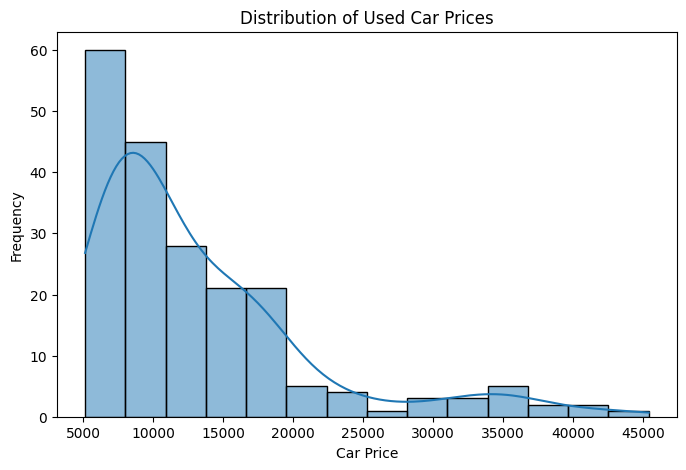

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df['price'], kde=True)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Frequency")

plt.show()

Correlation Heatmap

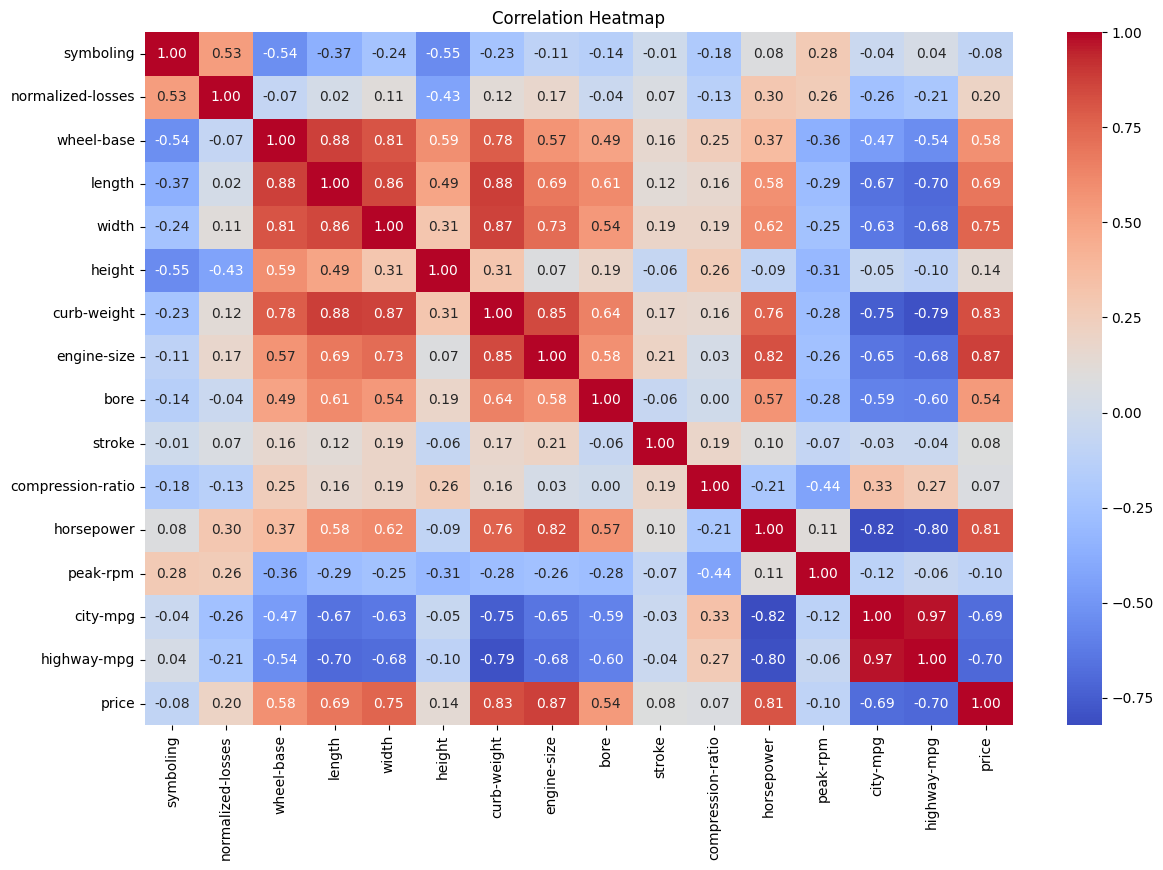

In [ ]:
plt.figure(figsize=(14, 9))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

Engine Size VS Price

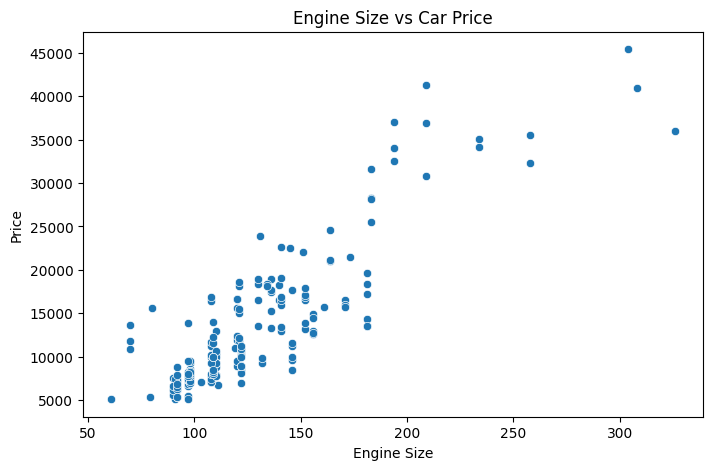

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='engine-size',
    y='price'
)

plt.title("Engine Size vs Car Price")
plt.xlabel("Engine Size")
plt.ylabel("Price")

plt.show()

Separate Features and Target Variable .

In [ ]:
X = df.drop('price', axis=1)

y = df['price']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (201, 25)
Target Variable Shape: (201,)


Identify Numerical and Categorical Features

In [ ]:
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['symboling', 'normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg']

Categorical Features:
['make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system']


Data Preprocessing

In [ ]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


Split Dataset into Training and Testing Sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (160, 25)
Testing Data: (41, 25)


Build Multiple Linear Regression Machine Learning Models

In [ ]:
mlr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

mlr_model.fit(X_train, y_train)

print("Multiple Linear Regression trained successfully!")

Multiple Linear Regression trained successfully!


Decision Tree Regression

In [ ]:
dt_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

print("Decision Tree Regression trained successfully!")

Decision Tree Regression trained successfully!


Random Forest Regression

In [ ]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest Regression trained successfully!")

Random Forest Regression trained successfully!


Model Prediction

In [ ]:
# Multiple Linear Regression
mlr_pred = mlr_model.predict(X_test)

# Decision Tree
dt_pred = dt_model.predict(X_test)

# Random Forest
rf_pred = rf_model.predict(X_test)

print("All predictions generated successfully!")

All predictions generated successfully!


Model Evaluation

In [ ]:
def evaluate_model(name, y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    mse = mean_squared_error(y_true, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_true, y_pred)

    return {
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }


results = []

results.append(
    evaluate_model(
        "Multiple Linear Regression",
        y_test,
        mlr_pred
    )
)

results.append(
    evaluate_model(
        "Decision Tree Regression",
        y_test,
        dt_pred
    )
)

results.append(
    evaluate_model(
        "Random Forest Regression",
        y_test,
        rf_pred
    )
)

results_df = pd.DataFrame(results)

print("Model Performance Comparison:")

display(results_df.round(2))

Model Performance Comparison:


,Model,MAE,MSE,RMSE,R2 Score
0,Multiple Linear Regression,1972.15,10576265.64,3252.12,0.91
1,Decision Tree Regression,1988.05,8683206.29,2946.73,0.93
2,Random Forest Regression,1909.49,9086422.35,3014.37,0.93


Compare Model Performance Using Graphs

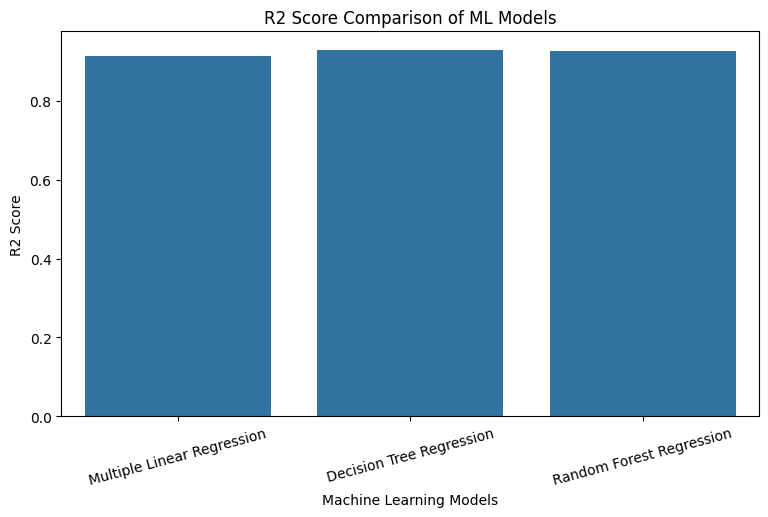

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title("R2 Score Comparison of ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")

plt.xticks(rotation=15)

plt.show()

RMSE Comparison

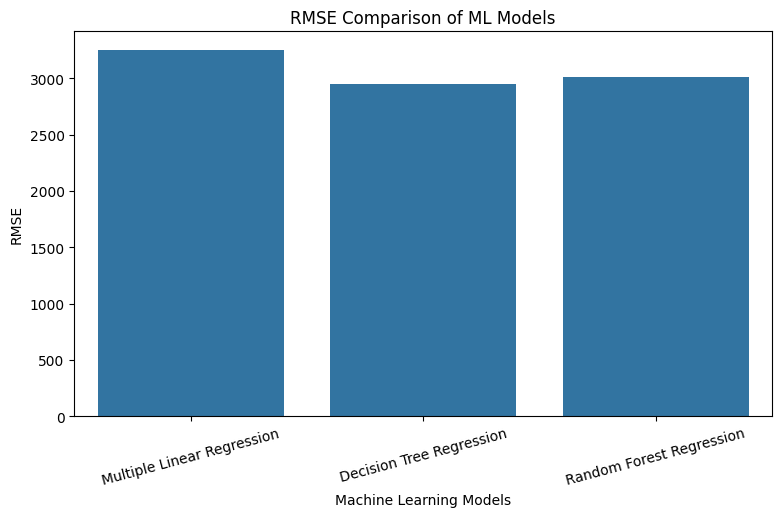

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title("RMSE Comparison of ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE")

plt.xticks(rotation=15)

plt.show()

Actual Price vs Predicted Price

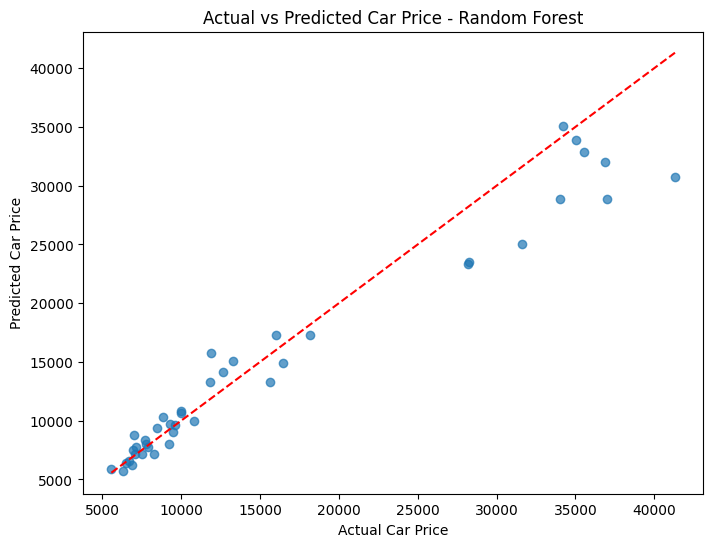

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")

plt.title("Actual vs Predicted Car Price - Random Forest")

plt.show()

Find the Best Performing Model

In [ ]:
best_model_name = results_df.loc[
    results_df['RMSE'].idxmin(),
    'Model'
]

print("Best Performing Model:", best_model_name)

Best Performing Model: Decision Tree Regression


Feature Importance

In [ ]:
rf_regressor = rf_model.named_steps['model']

feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

importance = rf_regressor.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features:")

display(feature_importance.head(15))

Top 15 Important Features:


,Feature,Importance
6,num__curb-weight,0.429203
7,num__engine-size,0.304316
11,num__horsepower,0.060988
14,num__highway-mpg,0.051590
13,num__city-mpg,0.036872
4,num__width,0.027757
2,num__wheel-base,0.014912
17,cat__make_bmw,0.010034
3,num__length,0.007640
12,num__peak-rpm,0.007194


Feature importance graph:

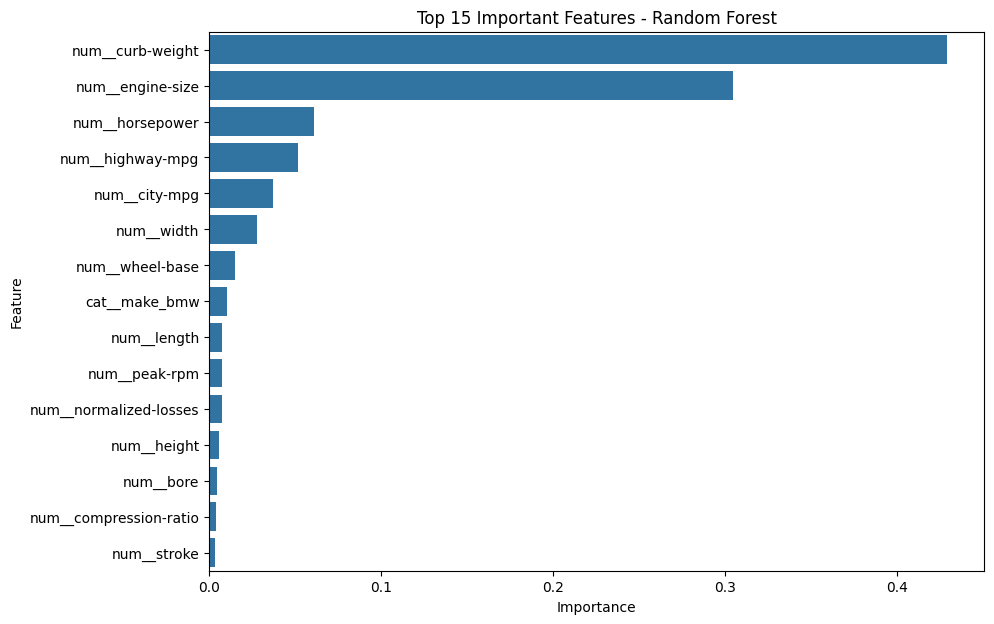

In [ ]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features - Random Forest")

plt.show()

Predict the Price of a New Car

In [ ]:
new_car = X_test.iloc[[0]].copy()

mlr_price = mlr_model.predict(new_car)[0]

dt_price = dt_model.predict(new_car)[0]

rf_price = rf_model.predict(new_car)[0]

print("Multiple Linear Regression Price:",
      round(mlr_price, 2))

print("Decision Tree Price:",
      round(dt_price, 2))

print("Random Forest Price:",
      round(rf_price, 2))

print("\nActual Car Price:",
      y_test.iloc[0])

Multiple Linear Regression Price: 7294.53
Decision Tree Price: 6692.0
Random Forest Price: 7142.8

Actual Car Price: 8249.0


Display all predictions in a table:

In [ ]:
prediction_comparison = pd.DataFrame({
    'Model': [
        'Multiple Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'Predicted Price': [
        mlr_price,
        dt_price,
        rf_price
    ]
})

display(prediction_comparison.round(2))

,Model,Predicted Price
0,Multiple Linear Regression,7294.53
1,Decision Tree,6692.00
2,Random Forest,7142.80


Save the Trained Models

In [ ]:
joblib.dump(mlr_model, 'multiple_linear_regression.pkl')

joblib.dump(dt_model, 'decision_tree.pkl')

joblib.dump(rf_model, 'random_forest.pkl')

print("All models saved successfully!")

All models saved successfully!


Download the models:

In [ ]:
from google.colab import files

files.download('multiple_linear_regression.pkl')

files.download('decision_tree.pkl')

files.download('random_forest.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Save Model Comparison Results

In [ ]:
results_df.to_csv(
    'model_comparison_results.csv',
    index=False
)

files.download('model_comparison_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>